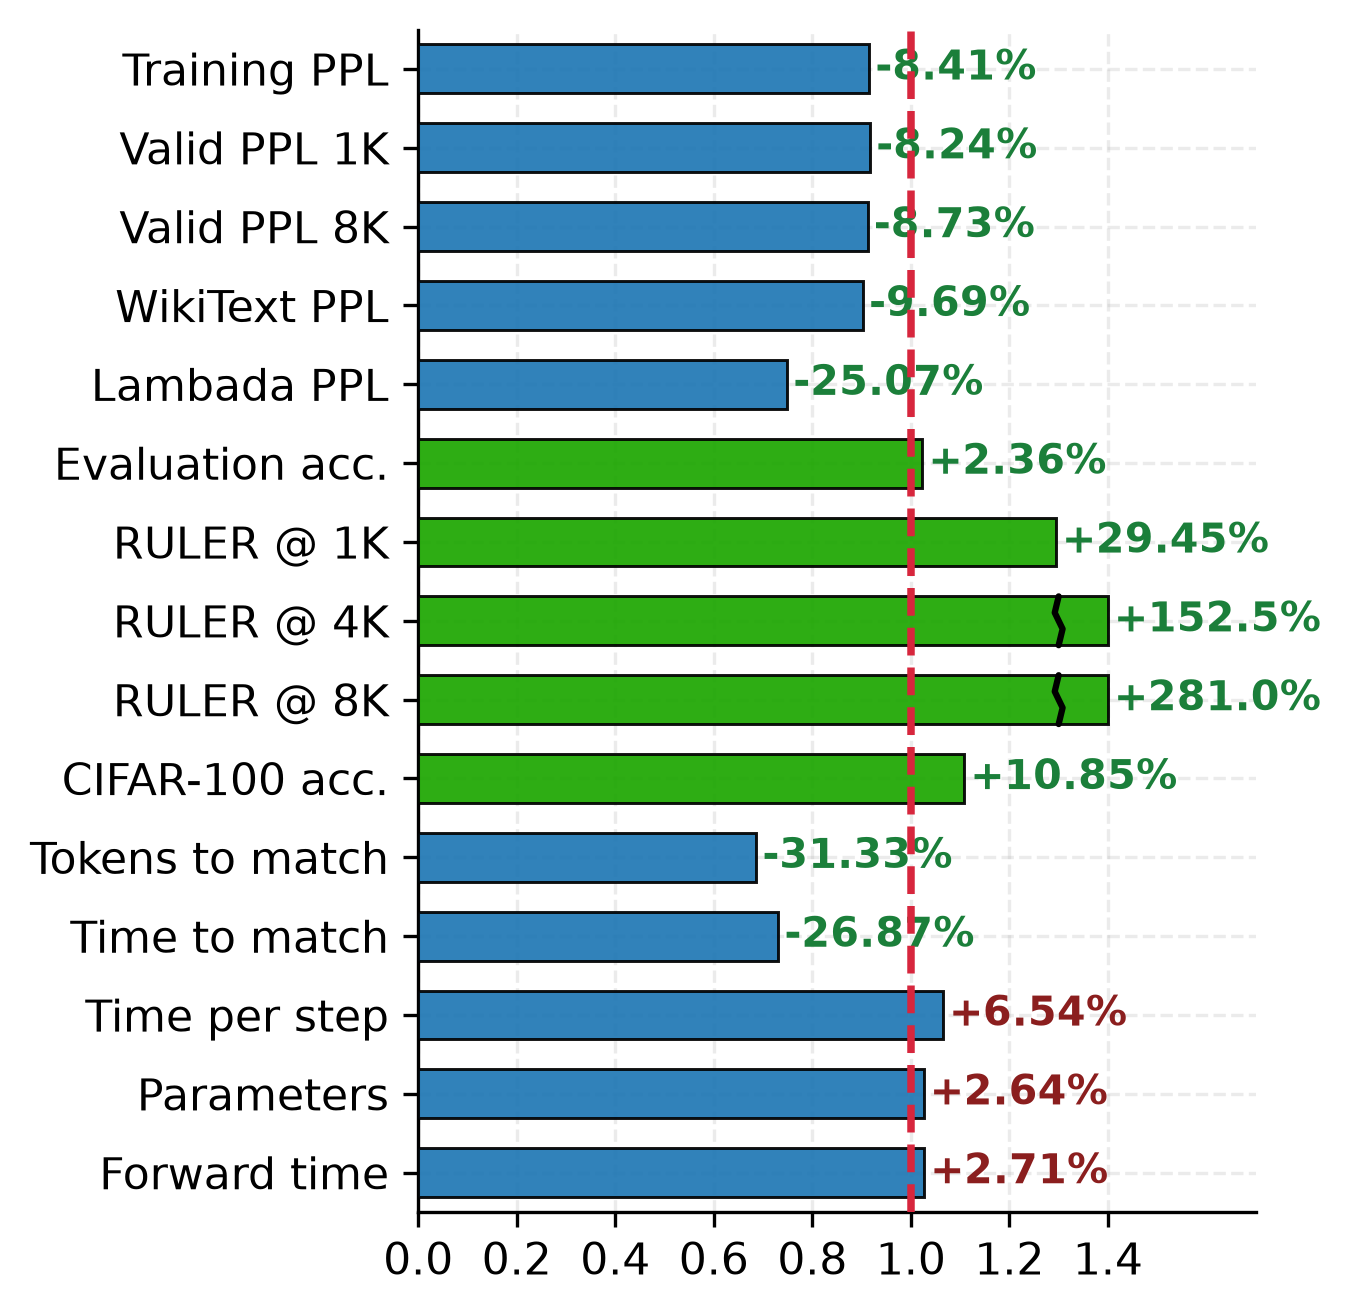

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import matplotlib as mpl
import math

mpl.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "grid.linestyle": "--",
        "axes.axisbelow": True,
    }
)

BLUE = "#1f77b4"
ORANGE = "#1ca600"
RED = "#D7263D"

rows = [
    ["Training PPL", "lower", math.exp(3.0316 - 3.1195)],
    ["Valid PPL 1K", "lower", 20.672 / 22.5272],
    ["Valid PPL 8K", "lower", 19.7405 / 21.6276],
    ["WikiText PPL", "lower", 42.05 / 46.56],
    ["Lambada PPL", "lower", 88.49 / 118.10],
    ["Evaluation acc.", "higher", 0.4475 / 0.4372],
    ["RULER @ 1K", "higher", 0.211 / 0.163],
    ["RULER @ 4K", "higher", 0.101 / 0.040],
    ["RULER @ 8K", "higher", 0.080 / 0.021],
    ["CIFAR-100 acc.", "higher", 0.695 / 0.627],
    ["Tokens to match", "lower", 2.06 / 3.0],
    ["Time to match", "lower", 1 - 0.2687],
    ["Time per step", "lower", 2.77 / 2.6],
    ["Parameters", "lower", 128.13 / 124.84],
    ["Forward time", "lower", 23.14 / 22.53],
]

labels = [r[0] for r in rows]
dirs = [r[1] for r in rows]
ratios = np.array([r[2] for r in rows])
pct_met = np.array([(r[2] - 1) * 100 for r in rows])

# ---- 断裂线参数 ----
BREAK_THRESHOLD = 1.5  # 超过该值触发断裂
BAR_HEIGHT = 0.62
DISPLAY_BAR_END = 1.40  # 视觉上柱子截断的长度
BREAK_X = 1.30  # 裂缝中心位置

fig, ax = plt.subplots(figsize=(4.5, 4.5), dpi=300)
y = np.arange(len(labels))

# ---------- 绘制柱状图 ----------
for yi, r, d in zip(y, ratios, dirs):
    color = BLUE if d == "lower" else ORANGE

    if r > BREAK_THRESHOLD:
        # 画截断柱
        ax.barh(
            yi,
            DISPLAY_BAR_END,
            height=BAR_HEIGHT,
            color=color,
            edgecolor="black",
            linewidth=0.7,
            zorder=3,
            alpha=0.92,
        )
        ymin = yi - BAR_HEIGHT / 2
        ymax = yi + BAR_HEIGHT / 2

        # 绘制黑色裂缝（折2次：4个点，3段线）
        dy = (ymax - ymin) / 3
        dx = 0.008  # 水平偏移幅度
        zx = [BREAK_X, BREAK_X - dx, BREAK_X + dx, BREAK_X]
        zy = [ymin, ymin + dy, ymin + 2 * dy, ymax]
        ax.plot(
            zx,
            zy,
            color="black",
            linewidth=1.5,
            zorder=6,
            solid_capstyle="round",
            solid_joinstyle="round",
        )
    else:
        ax.barh(
            yi,
            r,
            height=BAR_HEIGHT,
            color=color,
            edgecolor="black",
            linewidth=0.7,
            zorder=3,
            alpha=0.92,
        )

# RoPE baseline 红色虚线
ax.axvline(1.0, color=RED, linestyle="--", linewidth=1.8, zorder=4)

# ---------- 柱末端文本标注 ----------
for yi, r, p, d in zip(y, ratios, pct_met, dirs):
    good = (r < 1.0) if d == "lower" else (r > 1.0)
    color = "#1B7F3A" if good else "#8B1E1E"

    if r > BREAK_THRESHOLD:
        tag = f"{p:+.1f}%"
        label_x = DISPLAY_BAR_END + 0.012
    else:
        tag = f"{p:+.2f}%"
        label_x = r + 0.012

    ax.text(
        label_x,
        yi,
        tag,
        va="center",
        ha="left",
        fontsize=9.8,
        color=color,
        fontweight="bold",
    )

# ax.set_title("ConvPE / RoPE ratio")
# ---------- 坐标轴调整 ----------
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10.5)
ax.set_xlim(0, 1.70)
ax.set_xticks(np.arange(0, 1.41, 0.2))
# 精准贴合上下边界，解决第一根柱子上方间距问题
ax.set_ylim(len(y) - 0.5, -0.5)

# ---------- 图例 ----------
legend_elems = [
    Patch(facecolor=BLUE, edgecolor="black", label="The lower the better"),
    Patch(facecolor=ORANGE, edgecolor="black", label="The higher the better"),
    plt.Line2D(
        [0], [0], color=RED, linestyle="--", linewidth=1.8, label="RoPE baseline = 1.0"
    ),
]
# legend omitted: the caption explains the color coding

plt.tight_layout()
plt.savefig("overview.png", dpi=300, bbox_inches="tight")
plt.show()